# **California Cities: a quick data analysis**

## **1 · Import the tools**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'FreeSerif', 'DejaVu Serif']

## **2 · Load and inspect the table**

In [2]:
cities = pd.read_csv('california_cities.csv')
print('Rows and columns:', cities.shape)

Rows and columns: (482, 14)


In [3]:
cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


## **3 · Choose columns and check data quality**

In [4]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m           48
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         5
area_land_km2          4
area_water_km2         4
area_water_percent     5
dtype: int64

### **Q1 (a) · Check the water-area columns**

In [5]:
water_columns = ['area_water_sq_mi', 'area_water_km2', 'area_water_percent']
print('Data types:')
print(cities[water_columns].dtypes)
print()
print('Missing values:')
print(cities[water_columns].isna().sum())

Data types:
area_water_sq_mi      float64
area_water_km2        float64
area_water_percent    float64
dtype: object

Missing values:
area_water_sq_mi      1
area_water_km2        4
area_water_percent    5
dtype: int64


In [6]:
cities.loc[cities['area_water_km2'].isna(), ['city'] + water_columns]

,city,area_water_sq_mi,area_water_km2,area_water_percent
237,LosAltos,0.000,NaN,NaN
370,SanFrancisco,185.020,NaN,80.0
393,SantaMonica,0.001,NaN,NaN
443,UnionCity,0.000,NaN,NaN


All three columns are `float64`. `area_water_km2` has 4 missing values.

One of them is `SanFrancisco`, but its `area_water_sq_mi` is 185.02. Dropping missing rows would remove it from the ranking, so km² is filled from square miles in the next step.

In [7]:
cities["elevation_m"] = cities["elevation_m"].fillna(cities["elevation_ft"] * 0.3048)
cities["area_total_km2"] = cities["area_total_km2"].fillna(cities["area_total_sq_mi"] * 2.58999)
cities["area_land_km2"] = cities["area_land_km2"].fillna(cities["area_land_sq_mi"] * 2.58999)
cities["area_water_km2"] = cities["area_water_km2"].fillna(cities["area_water_sq_mi"] * 2.58999)

In [8]:
print('Missing values:')
cities.isna().sum()

Missing values:


Unnamed: 0             0
city                   0
latd                   0
longd                  0
elevation_m            8
elevation_ft          12
population_total       0
area_total_sq_mi       2
area_land_sq_mi        0
area_water_sq_mi       1
area_total_km2         1
area_land_km2          0
area_water_km2         0
area_water_percent     5
dtype: int64

In [9]:
cities.drop(columns=['elevation_ft', 'area_total_sq_mi', 'area_land_sq_mi', 'area_water_sq_mi'], inplace=True)
cities.head()

,Unnamed: 0,city,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0000,31765,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0000,20330,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,10.0584,75467,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,13.1064,18969,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0000,83089,19.766,19.763,0.003,0.01


In [10]:
cities.describe().round(2)

,Unnamed: 0,latd,longd,elevation_m,population_total,area_total_km2,area_land_km2,area_water_km2,area_water_percent
count,482.00,482.00,482.00,474.00,482.00,481.00,482.00,482.00,477.00
mean,240.50,36.10,-119.84,173.07,64894.93,47.80,43.62,4.09,5.30
std,139.29,2.30,2.15,303.56,203204.10,94.06,84.67,24.55,14.66
min,0.00,32.58,-124.26,-54.86,1.00,0.81,0.81,0.00,0.00
25%,120.25,33.98,-121.95,21.00,10902.00,9.62,9.08,0.00,0.00
50%,240.50,36.20,-119.71,62.50,29057.50,23.55,21.66,0.08,0.34
75%,360.75,37.89,-117.98,158.50,66466.50,51.77,49.44,0.62,1.87
max,481.00,41.96,-114.60,2402.00,3884307.00,1302.00,1214.00,479.20,84.58


### **Q1 (b) · Rank cities by water area**

In [11]:
top_water = cities.sort_values('area_water_km2', ascending=False).head(5)
top_water = top_water[['city', 'area_water_km2', 'area_water_percent']].reset_index(drop=True)
top_water['city'] = top_water['city'].str.replace(r'(?<=[a-z])(?=[A-Z])', ' ', regex=True)
top_water['area_water_km2'] = top_water['area_water_km2'].round(2)
top_water.index = top_water.index + 1
top_water.index.name = 'rank'
top_water

,city,area_water_km2,area_water_percent
rank,,,
1,San Francisco,479.20,80.00
2,San Diego,122.27,12.68
3,Los Angeles,88.00,6.70
4,Newport Beach,75.56,55.07
5,Coronado,64.06,75.72


San Francisco ranks first with 479.2 km², about 3.9 times San Diego (122.3 km²). Los Angeles, Newport Beach, and Coronado follow.

### **Q1 (c) · Horizontal bar chart**

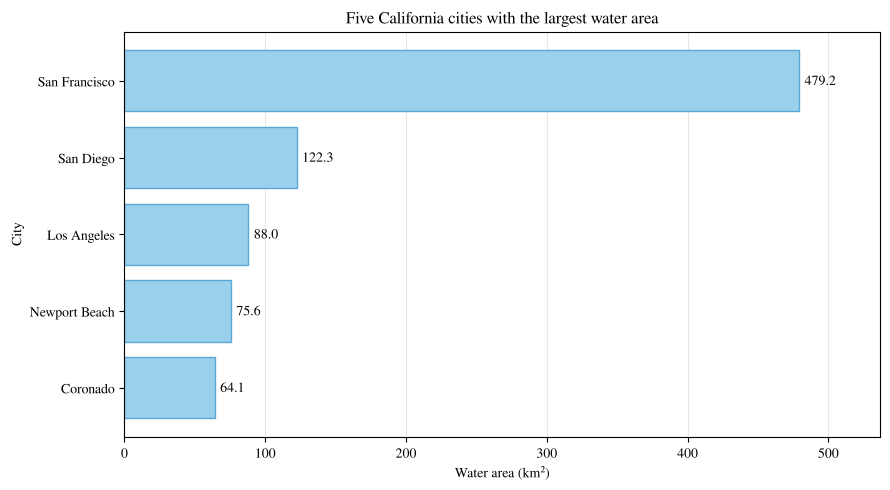

In [12]:
plot_data = top_water.sort_values('area_water_km2')

plt.figure(figsize=(9, 5))
bars = plt.barh(plot_data['city'], plot_data['area_water_km2'], color='#9AD0EC', edgecolor='#5BA8D6')
plt.bar_label(bars, fmt='%.1f', padding=4)
plt.title('Five California cities with the largest water area')
plt.xlabel('Water area (km²)')
plt.ylabel('City')
plt.xlim(0, plot_data['area_water_km2'].max() * 1.12)
plt.grid(axis='x', alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()
plt.show()

Water area is concentrated in coastal and bay cities. San Francisco is the clear outlier because its boundary includes bay and ocean waters (80% of its total area).

## **4 · Plot 1: a population map**

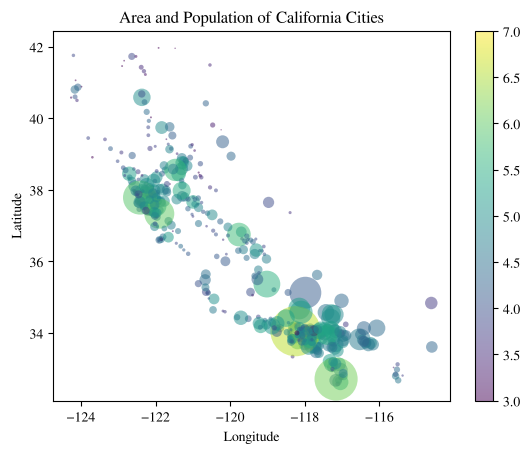

In [13]:
plt.scatter(
    cities['longd'],
    cities['latd'],
    cmap='viridis',
    c=np.log10(cities['population_total']),
    s=cities['area_total_km2'],
    linewidth=0, alpha=0.5
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.colorbar()
plt.clim(3, 7)

plt.title("Area and Population of California Cities")
plt.show()

## **5 · Plot 2: the ten most populous cities**

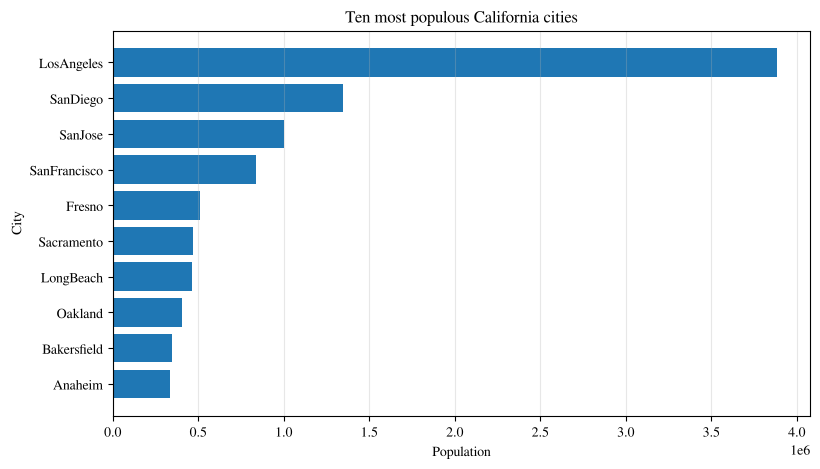

In [14]:
top_10 = cities.nlargest(10, 'population_total').sort_values('population_total')

plt.figure(figsize=(9, 5))
plt.barh(
    top_10['city'],
    top_10['population_total']
)
plt.xlabel('Population')
plt.ylabel('City')
plt.title('Ten most populous California cities')
plt.grid(axis='x', alpha=0.3)
plt.show()

## **6 · Plot 3: population and area**

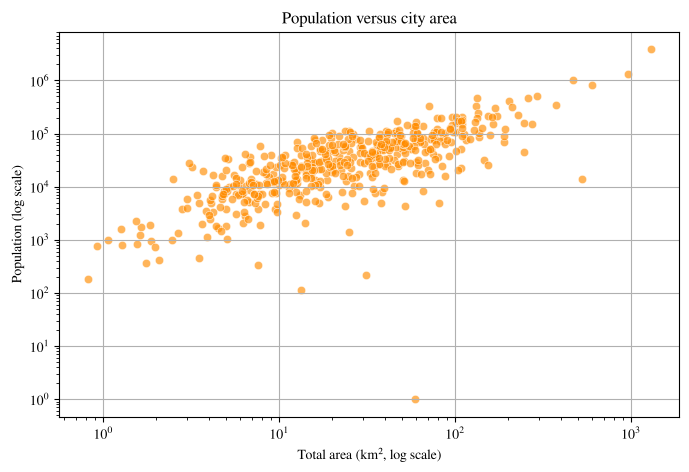

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(
    cities['area_total_km2'],
    cities['population_total'],
    color='darkorange',
    alpha=0.65,
    edgecolors='white',
    linewidth=0.5
)
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Total area (km², log scale)')
plt.ylabel('Population (log scale)')
plt.title('Population versus city area')
plt.grid()
plt.show()

## **8 · Plot 4: distribution of population density**

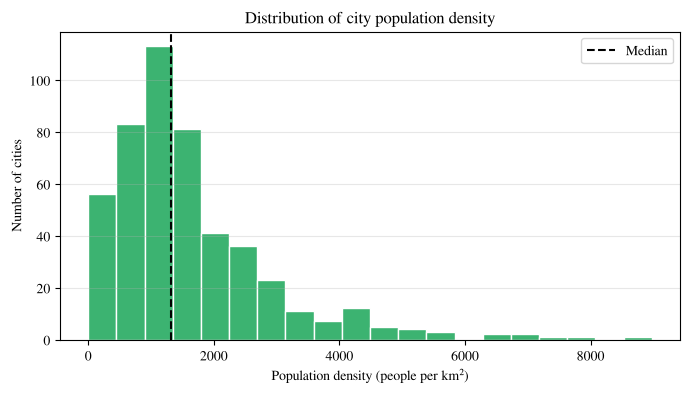

In [16]:
cities["population_density"] = cities["population_total"] / cities["area_land_km2"]

plt.figure(figsize=(8, 4))
plt.hist(cities['population_density'], bins=20, color='mediumseagreen', edgecolor='white')
plt.axvline(cities['population_density'].median(), color='black', linestyle='--', label='Median')
plt.xlabel('Population density (people per km²)')
plt.ylabel('Number of cities')
plt.title('Distribution of city population density')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()